In [ ]:
!pip install -q pandas matplotlib openpyxl numpy

cell 2


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, MultipleLocator, NullFormatter

# ---- matplotlib publication styling ----------------------------------------
plt.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["DejaVu Serif", "Times New Roman", "Times"],
    "font.size":        12,
    "axes.linewidth":   1.1,
    "mathtext.fontset": "dejavuserif",
    "savefig.dpi":      300,
})

# ---- energy window for parsing/comparison -----------------------------------
E_MIN, E_MAX = 0.0, 20.0          # MeV  — display window (0-20 MeV)

# ---- expected file names (rename your uploads to match, or edit here) -------
FILES = {
    "EXFOR": "Fe-58_n_p_Mn-58_exfor.csv",
    "TENDL": "Fe58_tendl.csv",
    "ENDF":  "Fe_58___n_p__JENDL_5_200_MeV_cross_section_data_data.txt",
    "JEFF":  "JEFF_Fe58_np_CrossSection_1MeV_to_40MeV.csv",
    "TALYS": "TALYS_DATA_for_Fe_58_csv.xlsx",
}

def _norm(s):
    return s.lower().replace(" ", "").replace("_", "").replace("-", "")

def resolve(key):
    sigs = {"EXFOR": "exfor", "TENDL": "tendl", "ENDF": "endf",
            "JEFF": "jeff", "TALYS": "talys"}
    want = sigs[key]
    for fn in os.listdir("."):
        n = _norm(fn)
        if want in n or (key == "ENDF" and "jendl" in n):
            return fn
    return None

B_TO_MB = 1000.0   # barns -> millibarns
EV_TO_MEV = 1e-6   # eV    -> MeV

cell 3

In [ ]:
def parse_exfor(path):
    """EXFOR experimental CSV: energy_MeV, cross_section_b, uncertainties,
    author, year. Returns a tidy DataFrame in MeV / mb. Hardened against
    duplicate columns and pandas .str-accessor quirks."""
    df = pd.read_csv(path)
    df = df.loc[:, ~df.columns.duplicated()]   # drop any duplicate-named columns

    def _get_col(frame, name, default):
        if name in frame.columns:
            col = frame[name]
            if isinstance(col, pd.DataFrame):   # safety: duplicate label slipped through
                col = col.iloc[:, 0]
            return col
        return pd.Series([default] * len(frame), index=frame.index)

    author_col = _get_col(df, "author", "Unknown").astype(str).apply(lambda x: x.strip())
    year_col   = pd.to_numeric(_get_col(df, "year", 0), errors="coerce").fillna(0).astype(int)

    out = pd.DataFrame({
        "energy_MeV":  pd.to_numeric(_get_col(df, "energy_MeV", np.nan), errors="coerce"),
        "xs_mb":       pd.to_numeric(_get_col(df, "cross_section_b", np.nan), errors="coerce") * B_TO_MB,
        "dE_MeV":      pd.to_numeric(_get_col(df, "d_energy_MeV", 0), errors="coerce").fillna(0),
        "dxs_mb":      pd.to_numeric(_get_col(df, "d_cross_section_b", 0), errors="coerce").fillna(0) * B_TO_MB,
        "author":      author_col,
        "year":        year_col,
    })
    out = out.dropna(subset=["energy_MeV", "xs_mb"])
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0]
    out["label"] = out["author"] + " (" + out["year"].astype(str) + ")"
    return out.reset_index(drop=True)


def parse_tendl(path):
    """TENDL CSV (TALYS YANDF export). Data already in MeV / mb;
    a long '#'-comment header precedes 'E,xs'."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip().strip(",").strip()
            if not s or s.startswith("#") or s.startswith('"'):
                continue
            if s.lower().startswith("e,") or s.lower() == "e,xs":
                continue
            parts = [p for p in s.replace(";", ",").split(",") if p != ""]
            if len(parts) < 2:
                continue
            try:
                e  = float(parts[0])
                xs = float(parts[1])
            except ValueError:
                continue
            rows.append((e, xs))
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)


def parse_endf(path):
    """ENDF / JENDL point file: 'E[eV]  Sig[b]  Interpolation'.
    Lines beginning with '#' are header. Convert eV->MeV, b->mb."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            s = line.strip()
            if not s or s.startswith("#"):
                continue
            parts = s.split()
            if len(parts) < 2:
                continue
            try:
                e_ev  = float(parts[0])
                sig_b = float(parts[1])
            except ValueError:
                continue
            rows.append((e_ev * EV_TO_MEV, sig_b * B_TO_MB))
    df = pd.DataFrame(rows, columns=["energy_MeV", "xs_mb"])
    df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
    df = df[df["xs_mb"] > 0].sort_values("energy_MeV")
    return df.reset_index(drop=True)


def parse_jeff(path):
    """JEFF CSV with columns Energy_eV, CrossSection_barns, Energy_MeV."""
    df = pd.read_csv(path)
    if "Energy_MeV" in df.columns:
        e = pd.to_numeric(df["Energy_MeV"], errors="coerce")
    else:
        e = pd.to_numeric(df["Energy_eV"], errors="coerce") * EV_TO_MEV
    xs = pd.to_numeric(df["CrossSection_barns"], errors="coerce") * B_TO_MB
    out = pd.DataFrame({"energy_MeV": e, "xs_mb": xs}).dropna()
    out = out[(out["energy_MeV"] >= E_MIN) & (out["energy_MeV"] <= E_MAX)]
    out = out[out["xs_mb"] > 0].sort_values("energy_MeV")
    return out.reset_index(drop=True)


def parse_talys(path):
    """TALYS data: 4 side-by-side (Energy[MeV], sigma[mb]) blocks, one per
    level-density model. Handles real .xlsx files AND files that are
    actually CSV/plain-text but were saved or renamed with an .xlsx
    extension (auto-detected via file signature). Returns a dict
    {model_name: DataFrame}."""

    # ---- detect real xlsx (zip archive) vs mis-labelled CSV/text ----------
    is_real_xlsx = False
    try:
        with open(path, "rb") as fh:
            is_real_xlsx = fh.read(4) == b"PK"
    except Exception:
        pass

    raw = None
    if is_real_xlsx:
        raw = pd.read_excel(path, header=None)
    else:
        for sep in [",", ";", "\t"]:
            try:
                candidate = pd.read_csv(path, header=None, sep=sep, engine="python")
                if candidate.shape[1] >= 2:
                    raw = candidate
                    break
            except Exception:
                continue
        if raw is None:
            # last resort: still try read_excel in case detection was wrong
            raw = pd.read_excel(path, header=None)

    titles = raw.iloc[0].tolist()

    MODEL_NAMES = {
        "constanttemperature": "CTM",
        "generalizedsuperfluid": "GSM",
        "backshiftedfermigas": "BSFM",
        "microscopic": "Microscopic (Skyrme)",
    }

    def key_for(title):
        t = str(title).lower().replace(" ", "")
        if "constanttemperature" in t or t == "ctm" or "(ctm)" in t:
            return "constanttemperature"
        if "generalizedsuperfluid" in t or "gsm" in t:
            return "generalizedsuperfluid"
        if "backshifted" in t or "bsfm" in t or "bfm" in t:
            return "backshiftedfermigas"
        if "microscopic" in t or "skyrme" in t:
            return "microscopic"
        return None

    models = {}
    for i, t in enumerate(titles):
        if not isinstance(t, str):
            continue
        k = key_for(t)
        if k is None:
            continue
        if i + 1 >= raw.shape[1]:
            continue
        e  = pd.to_numeric(raw.iloc[2:, i],     errors="coerce")
        xs = pd.to_numeric(raw.iloc[2:, i + 1], errors="coerce")
        df = pd.DataFrame({"energy_MeV": e.values, "xs_mb": xs.values}).dropna()
        df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
        df = df[df["xs_mb"] > 0].sort_values("energy_MeV").reset_index(drop=True)
        if len(df):
            models[MODEL_NAMES[k]] = df

    # ---- fallback: nothing matched by title text -> assume the standard --
    # 4-block layout (cols 0-1, 3-4, 6-7, 9-10) in file order
    if not models and raw.shape[1] >= 11:
        generic_names = ["Model A", "Model B", "Model C", "Model D"]
        for name, start_col in zip(generic_names, [0, 3, 6, 9]):
            if start_col + 1 >= raw.shape[1]:
                continue
            e  = pd.to_numeric(raw.iloc[2:, start_col],     errors="coerce")
            xs = pd.to_numeric(raw.iloc[2:, start_col + 1], errors="coerce")
            df = pd.DataFrame({"energy_MeV": e.values, "xs_mb": xs.values}).dropna()
            df = df[(df["energy_MeV"] >= E_MIN) & (df["energy_MeV"] <= E_MAX)]
            df = df[df["xs_mb"] > 0].sort_values("energy_MeV").reset_index(drop=True)
            if len(df):
                models[name] = df

    return models

cell 4


In [ ]:
# ---- load everything, handling missing files gracefully --------------------
PARSERS = {
    "EXFOR": parse_exfor,
    "TENDL": parse_tendl,
    "ENDF":  parse_endf,
    "JEFF":  parse_jeff,
    "TALYS": parse_talys,
}

data = {}
for key, parser in PARSERS.items():
    path = resolve(key)
    if path is None:
        print(f"[WARNING] {key}: file not found "
              f"(looked for '{FILES[key]}') — skipping.")
        data[key] = None
        continue
    try:
        data[key] = parser(path)
        if key == "TALYS":
            n = sum(len(df) for df in data[key].values())
            print(f"[OK] {key:5s}: {len(data[key])} models, {n:4d} total points  from '{path}'")
        else:
            print(f"[OK] {key:5s}: {len(data[key]):4d} points  from '{path}'")
    except Exception as e:
        print(f"[ERROR] {key}: failed to parse '{path}': {e}")
        data[key] = None

[OK] EXFOR:    8 points  from 'Fe-58_n_p_Mn-58 exfor.csv'
[OK] TENDL:   30 points  from 'Fe58 tendl.csv'
[OK] ENDF :   36 points  from 'Fe 58 ( n,p )JENDL 5 200 MeV cross section data data.txt'
[OK] JEFF :   38 points  from 'JEFF_Fe58_np_CrossSection_1MeV_to_40MeV.csv'
[OK] TALYS: 4 models,  140 total points  from 'TALYS DATA for Fe 58.csv.xlsx'


cell 5

Saved plot -> Fe58_np_combined_comparison_plot.png


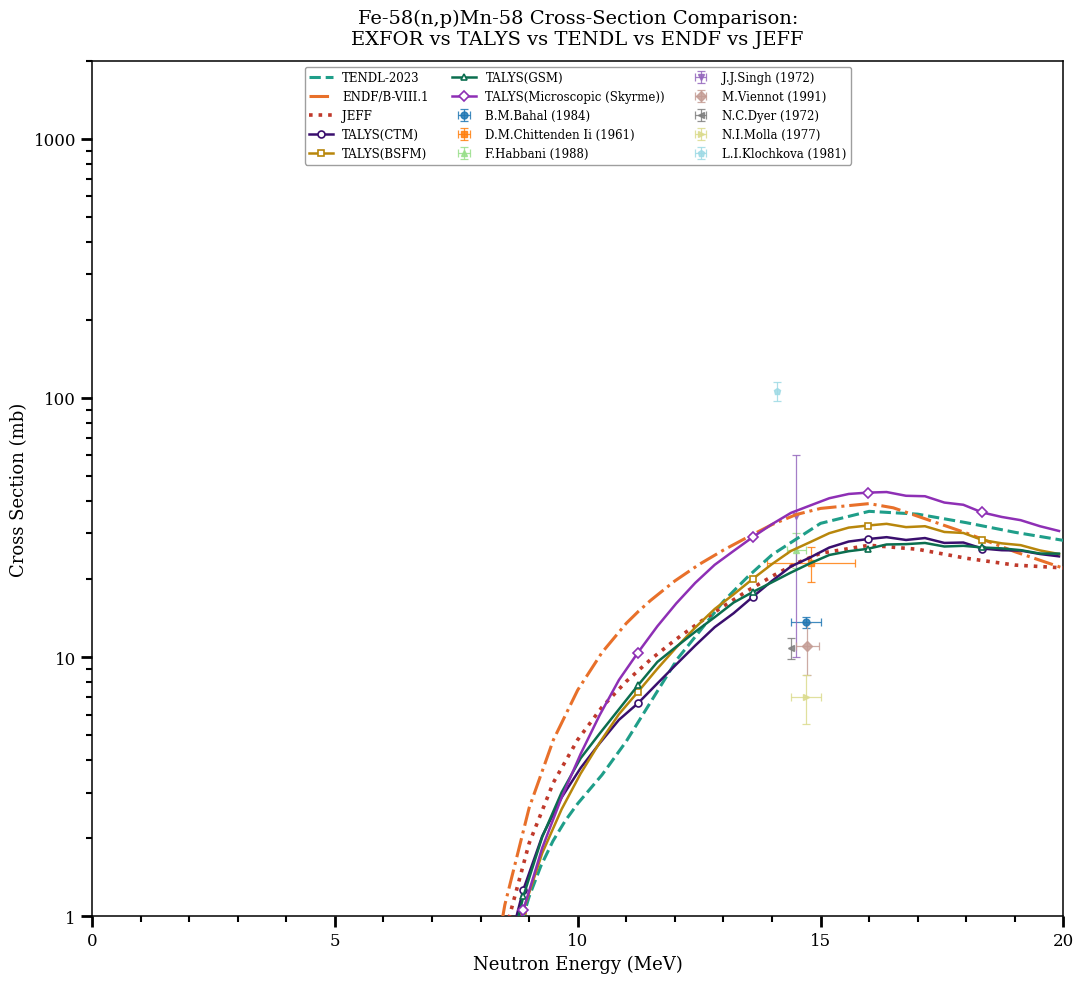

In [ ]:
import matplotlib.ticker as mticker

fig, ax = plt.subplots(figsize=(11, 10))

# ---- evaluated curves (TENDL / ENDF / JEFF) ---------------------------------
CURVE_STYLE = {
    "TENDL": dict(color="#1f9e89", ls="--", lw=2.2, label="TENDL-2023"),
    "ENDF":  dict(color="#e8702a", ls="-.", lw=2.2, label="ENDF/B-VIII.1"),
    "JEFF":  dict(color="#c0392b", ls=":",  lw=2.6, label="JEFF"),
}
for key in ["TENDL", "ENDF", "JEFF"]:
    df = data.get(key)
    if df is not None and len(df):
        ax.plot(df["energy_MeV"], df["xs_mb"], **CURVE_STYLE[key], zorder=3)

# ---- TALYS: 4 level-density models, distinct colors + markers --------------
TALYS_STYLE = {
    "CTM":                  dict(color="#3a0f6e", marker="o", markevery=6, ls="-", lw=1.8),
    "GSM":                  dict(color="#0b6e4f", marker="^", markevery=6, ls="-", lw=1.8),
    "BSFM":                 dict(color="#b8860b", marker="s", markevery=6, ls="-", lw=1.8),
    "Microscopic (Skyrme)": dict(color="#8e2fb5", marker="D", markevery=6, ls="-", lw=1.8),
}
talys_models = data.get("TALYS")
if talys_models:
    for name, df in talys_models.items():
        if df is not None and len(df):
            style = TALYS_STYLE.get(name, dict(color="gray", marker="x", ls="-", lw=1.5))
            ax.plot(df["energy_MeV"], df["xs_mb"],
                     markersize=5, markerfacecolor="white", markeredgewidth=1.2,
                     label=f"TALYS({name})", zorder=3, **style)

# ---- EXFOR experimental points, color-coded by author/year ------------------
exfor = data.get("EXFOR")
if exfor is not None and len(exfor):
    TOP_N = 10
    counts = exfor["label"].value_counts()
    top_labels = list(counts.index[:TOP_N])
    exfor = exfor[exfor["label"].isin(top_labels)].copy()
    exfor["plot_label"] = exfor["label"]
    plot_labels = top_labels

    cmap = plt.cm.tab20(np.linspace(0, 1, max(len(plot_labels), 1)))
    markers = ["o", "s", "^", "v", "D", "<", ">", "p", "*", "h", "X", "P"]

    for i, lab in enumerate(plot_labels):
        sub = exfor[exfor["plot_label"] == lab]
        ax.errorbar(
            sub["energy_MeV"], sub["xs_mb"],
            yerr=sub["dxs_mb"].where(sub["dxs_mb"] > 0, np.nan),
            xerr=sub["dE_MeV"].where(sub["dE_MeV"] > 0, np.nan),
            fmt=markers[i % len(markers)],
            color=cmap[i], ecolor=cmap[i],
            markersize=5, capsize=3, elinewidth=0.9, capthick=0.9,
            linestyle="none", alpha=0.85, label=lab, zorder=2,
        )

# ---- axes scales and range --------------------------------------------------
ax.set_xscale("linear")
ax.set_yscale("log")
ax.set_xlim(0, 20)
ax.set_ylim(1, 2000)

# Set x-axis ticks
ax.set_xticks([0, 5, 10, 15, 20])
# Set y-axis ticks
ax.set_yticks([1, 10, 100, 1000])
ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
ax.set_xlabel("Neutron Energy (MeV)", fontsize=13)
ax.set_ylabel("Cross Section (mb)", fontsize=13)
ax.set_title(
    "Fe-58(n,p)Mn-58 Cross-Section Comparison:\n"
    "EXFOR vs TALYS vs TENDL vs ENDF vs JEFF",
    fontsize=14, pad=12,
)

# ---- X AXIS (linear): major ticks at 0, 5, 10, 15, 20; minor every 1 -------
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.xaxis.set_minor_locator(MultipleLocator(1))

# ---- Y AXIS (log): major ticks at 1, 10, 100, 1000; minor sub-decade -------
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.yaxis.set_minor_formatter(NullFormatter())

ax.tick_params(which='major', length=8, width=2)
ax.tick_params(which='minor', length=4, width=1.5)

# ax.grid(which="major", ls="-",  lw=0.6, alpha=0.5)
# ax.grid(which="minor", ls=":",  lw=0.4, alpha=0.3)

ax.legend(loc="upper center", ncol=3, fontsize=8.5,
          framealpha=0.95, edgecolor="0.6")

fig.tight_layout()

OUT_PNG = "Fe58_np_combined_comparison_plot.png"
fig.savefig(OUT_PNG, dpi=700, bbox_inches="tight")
print(f"Saved plot -> {OUT_PNG}")

cell 6


In [ ]:
# ---- flatten TALYS dict {model_name: df} into separate sources -------------
flat_data = {}
for key, val in data.items():
    if key == "TALYS" and isinstance(val, dict):
        for model_name, df in val.items():
            flat_data[f"TALYS_{model_name}"] = df
    else:
        flat_data[key] = val

frames = []
for key, df in flat_data.items():
    if df is None or not len(df):
        continue
    tmp = df.copy()
    tmp["source"] = key
    if key == "EXFOR":
        tmp = tmp[["source", "energy_MeV", "xs_mb", "dE_MeV", "dxs_mb",
                   "author", "year"]]
    else:
        tmp = tmp[["source", "energy_MeV", "xs_mb"]]
        tmp["dE_MeV"] = np.nan
        tmp["dxs_mb"] = np.nan
        tmp["author"] = np.nan
        tmp["year"]   = np.nan
    frames.append(tmp)

combined = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
combined = combined.sort_values(["source", "energy_MeV"]).reset_index(drop=True)

OUT_CSV = "Fe58_np_parsed_data.csv"
combined.to_csv(OUT_CSV, index=False)
print(f"Saved data -> {OUT_CSV}  ({len(combined)} rows)")

# ---- summary statistics file ------------------------------------------------
OUT_TXT = "Fe58_np_summary_statistics.txt"
with open(OUT_TXT, "w") as f:
    f.write("Fe-58(n,p)Mn-58 Cross-Section Data — Summary Statistics\n")
    f.write("=" * 60 + "\n")
    f.write(f"Comparison energy window: {E_MIN}-{E_MAX} MeV\n\n")
    for key, df in flat_data.items():
        f.write(f"[{key}]\n")
        if df is None or not len(df):
            f.write("  (no data / file missing)\n\n")
            continue
        emin = df["energy_MeV"].min(); emax = df["energy_MeV"].max()
        xmin = df["xs_mb"].min(); xmax = df["xs_mb"].max()
        f.write(f"  points        : {len(df)}\n")
        f.write(f"  energy range  : {emin:.4g} - {emax:.4g} MeV\n")
        f.write(f"  xs min        : {xmin:.4g} mb\n")
        f.write(f"  xs max        : {xmax:.4g} mb\n")
        if key == "EXFOR":
            n_auth = df["author"].nunique()
            ymin = int(df["year"].min()); ymax = int(df["year"].max())
            f.write(f"  unique authors: {n_auth}\n")
            f.write(f"  year range    : {ymin}-{ymax}\n")
        f.write("\n")
print(f"Saved stats -> {OUT_TXT}")
print("\n".join(open(OUT_TXT).read().splitlines()))

Saved data -> Fe58_np_parsed_data.csv  (252 rows)
Saved stats -> Fe58_np_summary_statistics.txt
Fe-58(n,p)Mn-58 Cross-Section Data — Summary Statistics
Comparison energy window: 0.0-20.0 MeV

[EXFOR]
  points        : 8
  energy range  : 14.1 - 14.8 MeV
  xs min        : 7 mb
  xs max        : 106 mb
  unique authors: 8
  year range    : 1961-1991

[TENDL]
  points        : 30
  energy range  : 6 - 20 MeV
  xs min        : 1.12e-11 mb
  xs max        : 36.5 mb

[ENDF]
  points        : 36
  energy range  : 5.997 - 20 MeV
  xs min        : 0.001 mb
  xs max        : 39.09 mb

[JEFF]
  points        : 38
  energy range  : 5.819 - 20 MeV
  xs min        : 4.732e-11 mb
  xs max        : 27 mb

[TALYS_CTM]
  points        : 35
  energy range  : 6.52 - 19.91 MeV
  xs min        : 6.303e-06 mb
  xs max        : 29.01 mb

[TALYS_BSFM]
  points        : 35
  energy range  : 6.52 - 19.91 MeV
  xs min        : 5.496e-06 mb
  xs max        : 32.67 mb

[TALYS_GSM]
  points        : 35
  energy rang

In [ ]:
plt.show()